# Notebook 3: U-Net trained on all 23 CESM2 runs (final model)
ECS 289G Project 1, Group 5 (CESM2)

Goal: train only on CESM2 output, predict the tropical Pacific SST anomaly map, and get the Niño 3.4 index 3 months
ahead (τ = 3) from the predicted map. We compare against persistence and a linear inverse model (LIM).

This is our final model, the U-Net trained on all 23 runs. This notebook also fits the LIM baseline, makes the 3-month forecast for Dec 2026 from ecs289g_realworld_inputs_CESM2.nc, and compares all the models using the results saved by notebooks 1 and 2.

Part A was run on Kaggle (T4 GPU).

Data split (same years for every run):

| | Years | Used for |
|---|---|---|
| Train | 1850–1955 of each historical run + years 2027–2100 of the 12 SSP runs (r4, r10, r11) | fitting the weights |
| Validation | r4 historical 1961–1980 | early stopping only |
| Test | r4 historical 1986–2014 (348 start months) | scored once, at the end |

We do not use any simulated years between 2016 and 2026 for training or validation, so nothing overlaps with the
real-world file (Oct 2016 - Sep 2026). All runs share the same forcing, so none of them is trained on 1956-2014 either,
because that would overlap with the r4 test years.

In [1]:
# settings
MODEL_NAME = "U-Net, 23 runs (final)"
TAG = "unet_23runs"
ARCH = "unet"
MEMBERS = [f"r{i}i1p1f1" for i in range(1, 12)]
USE_SSP = True  # SSP runs of r4, r10, r11, years >= 2027
SEEDS, EPOCHS, PATIENCE, BATCH, LR, WIDTH = 5, 30, 6, 64, 1e-3, 32
SMOKE = False  # True = quick test run
if SMOKE:
    MEMBERS, SEEDS, EPOCHS = ["r4i1p1f1"], 1, 1
MAX_BATCHES = 5 if SMOKE else 0

In [2]:
# extra packages for reading CMIP6 from Pangeo
import importlib.util, subprocess, sys
if importlib.util.find_spec("xmip") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "intake-esm==2025.12.12", "xmip==0.7.2", "zarr==3.1.6",
                    "xarray==2026.9.0", "gcsfs", "fsspec", "cftime", "netCDF4", "dask"], check=True)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.6/58.6 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.7/295.7 kB 11.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 43.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 51.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.6/10.6 MB 62.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.8/80.8 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.5/68.5 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 40.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.4/38.4 MB 19.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 57.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 45.7 M

In [3]:
import glob, os, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.interpolate import LinearNDInterpolator, NearestNDInterpolator
from scipy.spatial import Delaunay
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

ON_KAGGLE = Path("/kaggle/working").exists()
WORK = Path("/kaggle/working") if ON_KAGGLE else Path("outputs")
DATA = Path("/tmp/enso_data") if ON_KAGGLE else Path("enso_data")
for d in (WORK / "models", WORK / "results", WORK / "figures", DATA): d.mkdir(parents=True, exist_ok=True)
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = DEV.type == "cuda"
print("device:", DEV, torch.cuda.get_device_name() if AMP else "")

device: cuda Tesla T4


## 1. Grid and definitions
All maps (CESM2 and the real-world file) go onto the same 1° grid over the tropical Pacific (24.5S-24.5N, 115.5E-65.5W).
That is 50 x 180 cells, 7,983 of them ocean, and the model only uses the ocean cells.

- Anomaly: value minus the 1985-2014 average for that calendar month (each run uses its own climatology).
- Relative SST: SST anomaly minus the 20S-20N mean at the same time step. This takes out global warming, which would
  otherwise look like a permanent El Niño. Our target is the relative Niño 3.4 index (5S-5N, 170W-120W), scaled to have
  the same 1985-2014 spread as the normal index.

In [4]:
LAT = np.arange(-24.5, 25.0, 1.0)
LON = np.arange(115.5, 295.0, 1.0)
AREA_W = np.cos(np.deg2rad(LAT))[:, None] * np.ones((1, LON.size))
GLON, GLAT = np.meshgrid(LON, LAT)
NINO34 = (190, 240, -5, 5)
TROP = (115, 295, -20, 20)
ALL = (0, 360, -90, 90)
LEADS = np.arange(1, 13); NL = len(LEADS)
NLAG = 3  # months t, t-1, t-2
TRAIN_YEARS, VAL_YEARS, TEST_YEARS, SSP_FROM = (1850, 1955), (1961, 1980), (1986, 2014), 2027
TEST_RUN = "r4i1p1f1_historical"
VARS = ["R", "Z", "mlotst", "tauu", "tauv", "pr"]


def box_mask(lon0, lon1, lat0, lat1):
    return (GLAT >= lat0) & (GLAT <= lat1) & (GLON >= lon0) & (GLON <= lon1)


def cell_mean(X, box, ocean):
    w = (AREA_W * box_mask(*box))[ocean]
    return X @ w / w.sum()


def years_months(times):
    s = pd.Index([f"{t.year:04d}-{t.month:02d}" if hasattr(t, "year") else str(t)[:7] for t in times])
    return s.str[:4].astype(int).values, s.str[5:7].astype(int).values

## 2. Download and preprocess CESM2
For each run we load six variables (tos, zos, mlotst, tauu, tauv, pr), crop them to the tropical
Pacific, subtract that run's 1985-2014 monthly climatology (the SSP runs use the climatology of their historical run), and
interpolate onto the ocean cells of the 1° grid. Then we compute relative SST and relative sea level. Each run is saved
as an .npz file in a temporary folder.

In [5]:
import gcsfs, intake
from xmip.preprocessing import combined_preprocessing

SSPS = ["ssp126", "ssp245", "ssp370", "ssp585"]
if SMOKE: SSPS = ["ssp245"]
BASE = slice("1985-01", "2014-12")
FIELDS = {"tos": ("Omon", 1.0), "zos": ("Omon", 1.0), "mlotst": ("Omon", 1.0),
          "tauu": ("Amon", 1.0), "tauv": ("Amon", 1.0), "pr": ("Amon", 86400.0)}  # pr in mm/day
DROP = ["time_bnds", "time_bounds", "lat_bnds", "lon_bnds", "bounds_lat", "bounds_lon"]
fs = gcsfs.GCSFileSystem(token="anon")
cat = intake.open_esm_datastore("https://storage.googleapis.com/cmip6/pangeo-cmip6.json")


def find(member, exp, var, table):
    df = cat.search(source_id="CESM2", member_id=member, experiment_id=exp, variable_id=var,
                    table_id=table, grid_label="gn").df
    return df.zstore.iloc[0] if len(df) else None


def load(store, var, table):
    ds = xr.open_zarr(fs.get_mapper(store), consolidated=True, drop_variables=DROP, use_cftime=True)
    if table == "Amon":
        return ds[var].sel(time=slice(None, "2100-12")).squeeze(drop=True).sel(
            lat=slice(-30, 30), lon=slice(105, 305)).astype("float32").load()
    da = combined_preprocessing(ds).squeeze(drop=True)[var].sel(time=slice(None, "2100-12"))
    lat, lon = da.lat.load(), da.lon.load()
    yy, xx = np.where(((lat >= -27) & (lat <= 27) & (lon >= 110) & (lon <= 300)).values)
    ydim, xdim = lat.dims
    return da.isel({ydim: slice(yy.min(), yy.max() + 1), xdim: slice(xx.min(), xx.max() + 1)}).astype("float32").load()


def ocean_mask_from(tos):
    pts = np.c_[tos.lon.values.ravel() % 360, tos.lat.values.ravel()]
    sea = np.isfinite(tos.isel(time=0).values.ravel())
    return NearestNDInterpolator(pts, sea.astype(float))(np.c_[GLON.ravel(), GLAT.ravel()]).reshape(GLAT.shape) > 0.5


def to_cells(anom, ocean):
    # interpolate onto the ocean cells of the 1 degree grid
    tgt = np.c_[GLON[ocean], GLAT[ocean]]
    if anom.lat.ndim == 1:
        g = anom.interp(lat=xr.DataArray(tgt[:, 1], dims="c"), lon=xr.DataArray(tgt[:, 0], dims="c"))
        out = g.transpose("time", "c").values
    else:
        vals = anom.transpose("time", *anom.lat.dims).values.reshape(anom.sizes["time"], -1)
        pts = np.c_[anom.lon.values.ravel() % 360, anom.lat.values.ravel()]
        ok = np.isfinite(vals).all(0)
        out = LinearNDInterpolator(Delaunay(pts[ok]), vals[:, ok].T)(tgt)
        gap = ~np.isfinite(out).all(1)
        out[gap] = NearestNDInterpolator(pts[ok], vals[:, ok].T)(tgt[gap])
        out = out.T
    assert np.isfinite(out).all(), "ocean cell left unfilled"
    return out.astype("float32")


def anomaly(da, clim):
    return (da.groupby("time.month") - clim).drop_vars("month")


def prepare_member(member):
    exps = ["historical"] + (SSPS if USE_SSP else [])
    todo = [e for e in exps if not (DATA / f"{member}_{e}.npz").exists()]
    if not todo: print(member, "done already"); return
    t0 = time.time()
    hist = {v: load(find(member, "historical", v, tab), v, tab) * k for v, (tab, k) in FIELDS.items()}
    clim = {v: d.sel(time=BASE).groupby("time.month").mean("time") for v, d in hist.items()}
    for exp in todo:
        if exp == "historical": raw = hist
        else:
            stores = {v: find(member, exp, v, tab) for v, (tab, k) in FIELDS.items()}
            if None in stores.values(): continue  # only r4, r10, r11 have SSPs
            raw = {v: load(stores[v], v, FIELDS[v][0]) * FIELDS[v][1] for v in FIELDS}
        yr, mo = years_months(raw["tos"].time.values)
        for v, d in raw.items():
            assert (years_months(d.time.values)[0] == yr).all(), (member, exp, v)
        ocean = ocean_mask_from(raw["tos"])
        cells = {v: to_cells(anomaly(raw[v], clim[v]), ocean) for v in FIELDS}
        tos, zos = cells.pop("tos"), cells.pop("zos")
        out = dict(R=tos - cell_mean(tos, TROP, ocean)[:, None],
                   Z=zos - cell_mean(zos, ALL, ocean)[:, None], **cells)
        np.savez(DATA / f"{member}_{exp}.npz", **{k: v.astype("float16") for k, v in out.items()},
                 n34=cell_mean(tos, NINO34, ocean).astype("float32"), trop=cell_mean(tos, TROP, ocean).astype("float32"),
                 year=yr, month=mo, ocean=ocean)
        print(f"{member} {exp}: {len(yr)} months, {int(ocean.sum())} ocean cells ({time.time() - t0:.0f}s)", flush=True)
        t0 = time.time()
    del hist


for m in sorted(MEMBERS, key=lambda m: m != "r4i1p1f1"):
    prepare_member(m)
print(sorted(p.name for p in DATA.glob("*.npz")))

r4i1p1f1 historical: 1980 months, 7983 ocean cells (25s)
r4i1p1f1 ssp126: 1032 months, 7983 ocean cells (16s)
r4i1p1f1 ssp245: 1032 months, 7983 ocean cells (14s)
r4i1p1f1 ssp370: 1032 months, 7983 ocean cells (15s)
r4i1p1f1 ssp585: 1032 months, 7983 ocean cells (14s)
r1i1p1f1 historical: 1980 months, 7983 ocean cells (23s)
r2i1p1f1 historical: 1980 months, 7983 ocean cells (23s)
r3i1p1f1 historical: 1980 months, 7983 ocean cells (23s)
r5i1p1f1 historical: 1980 months, 7983 ocean cells (24s)
r6i1p1f1 historical: 1980 months, 7983 ocean cells (25s)
r7i1p1f1 historical: 1980 months, 7983 ocean cells (23s)
r8i1p1f1 historical: 1980 months, 7983 ocean cells (25s)
r9i1p1f1 historical: 1980 months, 7983 ocean cells (25s)
r10i1p1f1 historical: 1980 months, 7983 ocean cells (25s)
r10i1p1f1 ssp126: 1032 months, 7983 ocean cells (16s)
r10i1p1f1 ssp245: 1032 months, 7983 ocean cells (16s)
r10i1p1f1 ssp370: 1032 months, 7983 ocean cells (17s)
r10i1p1f1 ssp585: 1032 months, 7983 ocean cells (16s)
r

## 3. Training, validation and test samples
One sample = one start month t. The inputs are months t, t-1 and t-2 and the targets are the maps at t+1 ... t+12. We only
keep samples where all of these months are in the same run. The SSP runs are detrended first (quadratic trend per grid
cell) and we only use their years from 2027 on.

In [6]:
def detrend(A):
    # remove a quadratic trend per cell (SSP runs)
    tt = np.linspace(-1, 1, len(A))
    c = np.polynomial.polynomial.polyfit(tt, A, 2)
    return A - np.polynomial.polynomial.polyval(tt, c).T


files = sorted(DATA.glob("*.npz"))
names = [f.stem for f in files if f.stem.split("_")[0] in MEMBERS and (USE_SSP or "ssp" not in f.stem)]
names = sorted(names, key=lambda n: n != TEST_RUN)
runs = {n: np.load(DATA / f"{n}.npz") for n in names}
OCEAN = runs[TEST_RUN]["ocean"]; NC = int(OCEAN.sum())
X = {v: [] for v in VARS}; year, month, run_id = [], [], []
for i, (n, z) in enumerate(runs.items()):
    assert (z["ocean"] == OCEAN).all()
    for v in VARS:
        a = z[v].astype("float32"); X[v].append(detrend(a) if "ssp" in n else a)
    year.append(z["year"]); month.append(z["month"]); run_id.append(np.full(len(z["year"]), i))
X = {v: np.concatenate(a) for v, a in X.items()}
year, month, run_id = np.concatenate(year), np.concatenate(month), np.concatenate(run_id)
is_ssp = np.array(["ssp" in n for n in names])[run_id]
T = len(year)

# scale factor: relative Nino 3.4 gets the same 1985-2014 std as the normal index (computed on r4)
z4 = runs[TEST_RUN]; b = (z4["year"] >= 1985) & (z4["year"] <= 2014)
SCALE = float(z4["n34"][b].std() / (z4["n34"] - z4["trop"])[b].std())
nino_true = cell_mean(X["R"], NINO34, OCEAN) * SCALE


def same_run(k):
    t = np.arange(T); s = t + k; ok = (s >= 0) & (s < T)
    ok[ok] = run_id[s[ok]] == run_id[t[ok]]
    return ok


has_lags, has_tgt = same_run(-(NLAG - 1)), same_run(NL)
in_years = lambda a, b: (year >= a) & (year <= b)
train_mask = np.where(is_ssp, year >= SSP_FROM, in_years(*TRAIN_YEARS))
idx_train = np.where(has_lags & has_tgt & train_mask)[0]
idx_val = np.where(has_lags & has_tgt & (run_id == 0) & in_years(*VAL_YEARS))[0]
idx_test = np.where(has_lags & (run_id == 0) & in_years(*TEST_YEARS))[0]
assert not ((year[idx_train] >= 2016) & (year[idx_train] <= 2026)).any(), "simulated 2016-2026 must not be in training"
assert not ((year[idx_val] >= 2016) & (year[idx_val] <= 2026)).any()
STD = {v: float(X[v][idx_train].std()) for v in VARS}
print(f"{len(runs)} runs ({int(sum('ssp' in n for n in names))} SSP) | samples: train {len(idx_train)}, "
      f"val {len(idx_val)}, test {len(idx_test)} | training years {year[idx_train].min()}-{year[idx_train].max()}, "
      f"none in 2016-2026 | relative-index scale {SCALE:.3f}")

23 runs (12 SSP) | samples: train 24482, val 240, test 348 | training years 1850-2099, none in 2016-2026 | relative-index scale 1.301


## 4. Model
Input: 21 channels on the 50 x 180 grid (6 variables x 3 months, plus the ocean mask and sin/cos of the month).
Output: 12 maps of relative SST anomaly for leads 1-12. Niño 3.4 is the average of the predicted map over the box.

- U-Net (2.6M parameters): downsamples to 2°, two conv levels, a dense bottleneck so every output cell can see the whole
  basin (warm water in the west builds up before El Niño shows in the east), and a skip connection.
- ResNet (about 3x the parameters): ResNet-18 style encoder with 6 residual blocks and a dense head, no skip connections.

The loss is the area-weighted map MSE plus the MSE of the Niño 3.4 box mean. We use AdamW with a cosine learning rate and
early stopping on the validation set.

In [7]:
def block(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.GELU(),
                         nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.GELU())


class UNet(nn.Module):
    def __init__(self, cin, cout, w=32, latent=256, p=0.2):
        super().__init__()
        self.e1, self.e2 = block(cin, w), block(w, 2 * w)
        self.squeeze = nn.Conv2d(2 * w, 8, 1)
        self.dense = nn.Sequential(nn.Flatten(), nn.Dropout(p), nn.Linear(8 * 13 * 46, latent), nn.GELU(),
                                   nn.Dropout(p), nn.Linear(latent, 8 * 13 * 46))
        self.expand = nn.Conv2d(8, 2 * w, 1)
        self.d1 = block(3 * w, w)
        self.out = nn.Conv2d(w, cout, 1)

    def forward(self, x):
        x = F.avg_pool2d(F.pad(x, (2, 2, 1, 1)), 2)
        e1 = self.e1(x); e2 = self.e2(F.max_pool2d(e1, 2))
        b = e2 + self.expand(self.dense(self.squeeze(e2)).view(-1, 8, 13, 46))
        d1 = self.d1(torch.cat([F.interpolate(b, scale_factor=2), e1], 1))
        y = F.interpolate(self.out(d1), scale_factor=2, mode="bilinear", align_corners=False)
        return y[..., 1:-1, 2:-2]


class ResBlock(nn.Module):
    def __init__(self, i, o, stride=1):
        super().__init__()
        self.c1, self.b1 = nn.Conv2d(i, o, 3, stride, 1, bias=False), nn.BatchNorm2d(o)
        self.c2, self.b2 = nn.Conv2d(o, o, 3, 1, 1, bias=False), nn.BatchNorm2d(o)
        self.short = (nn.Identity() if stride == 1 and i == o
                      else nn.Sequential(nn.Conv2d(i, o, 1, stride, bias=False), nn.BatchNorm2d(o)))

    def forward(self, x):
        return F.gelu(self.b2(self.c2(F.gelu(self.b1(self.c1(x))))) + self.short(x))


class ResNet(nn.Module):
    def __init__(self, cin, cout, w=32, latent=512, p=0.2):
        super().__init__()
        self.cout = cout
        self.stem = nn.Sequential(nn.Conv2d(cin, 2 * w, 3, padding=1, bias=False), nn.BatchNorm2d(2 * w), nn.GELU())
        self.stages = nn.Sequential(ResBlock(2 * w, 2 * w), ResBlock(2 * w, 2 * w), ResBlock(2 * w, 4 * w, 2),
                                    ResBlock(4 * w, 4 * w), ResBlock(4 * w, 8 * w, 2), ResBlock(8 * w, 8 * w))
        self.squeeze = nn.Conv2d(8 * w, 16, 1)
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(p), nn.Linear(16 * 7 * 23, latent), nn.GELU(),
                                  nn.Dropout(p), nn.Linear(latent, cout * 13 * 46))
        self.refine = nn.Conv2d(cout, cout, 3, padding=1)

    def forward(self, x):
        x = F.avg_pool2d(F.pad(x, (2, 2, 1, 1)), 2)
        h = self.head(self.squeeze(self.stages(self.stem(x)))).view(-1, self.cout, 13, 46)
        h = F.interpolate(h, scale_factor=2, mode="bilinear", align_corners=False)
        h = h + self.refine(h)
        return F.interpolate(h, scale_factor=2, mode="bilinear", align_corners=False)[..., 1:-1, 2:-2]


ARCHS = {"unet": UNet, "resnet": ResNet}
CH_IN = NLAG * len(VARS) + 3


def grid_tensors(ocean):
    global H, W_, CELL, OCEAN_T, WMAP, W34, wcell, w34c
    H, W_ = ocean.shape
    CELL = torch.tensor(np.flatnonzero(ocean), device=DEV)
    OCEAN_T = torch.tensor(ocean, dtype=torch.float32, device=DEV)
    WMAP = torch.tensor(AREA_W * ocean / (AREA_W * ocean).sum(), dtype=torch.float32, device=DEV)
    w34 = AREA_W * ocean * box_mask(*NINO34)
    W34 = torch.tensor(w34 / w34.sum(), dtype=torch.float32, device=DEV)
    wcell = AREA_W[ocean] / AREA_W[ocean].sum()
    w34c = (AREA_W * box_mask(*NINO34))[ocean]


def to_device(arrs):
    return {v: torch.tensor(arrs[v] / STD[v], dtype=torch.float16, device=DEV) for v in VARS}


def to_grid(v):
    g = torch.zeros(v.shape[:-1] + (H * W_,), dtype=torch.float32, device=DEV)
    g[..., CELL] = v.float()
    return g.view(v.shape[:-1] + (H, W_))


def make_x(D, months, ix):
    # input channels for start months ix
    ix = torch.as_tensor(ix, device=DEV)
    x = to_grid(torch.stack([D[v][ix - k] for v in VARS for k in range(NLAG)], 1))
    ph = 2 * torch.pi * torch.as_tensor(months, device=DEV)[ix].float() / 12
    B = len(ix)
    const = torch.stack([OCEAN_T.expand(B, H, W_), torch.sin(ph)[:, None, None].expand(B, H, W_),
                         torch.cos(ph)[:, None, None].expand(B, H, W_)], 1)
    return torch.cat([x, const], 1)


def predict(model, Dx, months, ix, bs=128):
    model.eval(); out = []
    with torch.no_grad(), torch.autocast(DEV.type, enabled=AMP):
        for i in range(0, len(ix), bs):
            out.append(model(make_x(Dx, months, ix[i:i + bs])).float().cpu().numpy())
    return np.concatenate(out) * STD["R"]


def nino_from_cells(cells):
    return cells @ w34c / w34c.sum() * SCALE


def map_acc(P, Y):
    # pattern correlation between predicted and true maps
    P = P - (P * wcell).sum(1, keepdims=True); Y = Y - (Y * wcell).sum(1, keepdims=True)
    return (P * Y * wcell).sum(1) / np.sqrt((P * P * wcell).sum(1) * (Y * Y * wcell).sum(1))


def metrics(p, t):
    e = p - t
    return {"corr": np.corrcoef(p, t)[0, 1], "RMSE": np.sqrt(np.mean(e ** 2)), "MAE": np.mean(np.abs(e)),
            "bias": e.mean(), "R2": 1 - np.sum(e ** 2) / np.sum((t - t.mean()) ** 2)}

## 5. Training
We train 5 networks with different random seeds and average them; the spread between them is our uncertainty estimate.
The log shows the train and validation loss per epoch (* = new best validation loss, those weights are kept).

In [8]:
grid_tensors(OCEAN)
D = to_device(X)
VALID = torch.tensor(np.stack([np.r_[run_id[L:] == run_id[:-L], np.zeros(L, bool)] for L in LEADS], 1), device=DEV)


def make_y(ix):
    ix = torch.as_tensor(ix, device=DEV)
    y = to_grid(torch.stack([D["R"][(ix + L).clamp(max=T - 1)] for L in LEADS], 1))
    return torch.where(VALID[ix][:, :, None, None], y, torch.full_like(y, float("nan")))


def loss_fn(pred, y):
    ok = torch.isfinite(y); y = torch.nan_to_num(y); pred = pred.float()
    field = (((pred - y) ** 2 * ok) * WMAP).sum((-2, -1)).sum() / ok[..., 0, 0].sum().clamp(min=1)
    okl = ok[..., 25, 100]
    i_p, i_y = (pred * W34).sum((-2, -1)), (y * W34).sum((-2, -1))
    return field + (((i_p - i_y) ** 2) * okl).sum() / okl.sum().clamp(min=1)


def train_one(seed):
    torch.manual_seed(seed); np.random.seed(seed); rng = np.random.default_rng(seed)
    model = ARCHS[ARCH](CH_IN, NL, WIDTH).to(DEV)
    if seed == 0: print(f"{MODEL_NAME}: {sum(p.numel() for p in model.parameters()) / 1e6:.2f} M parameters")
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS)
    scaler = torch.amp.GradScaler(enabled=AMP)
    noisy = (torch.arange(CH_IN, device=DEV) < CH_IN - 3)[None, :, None, None]
    best, best_state, bad = np.inf, None, 0
    for ep in range(EPOCHS):
        model.train(); t0 = time.time(); tl = []
        for bi, b in enumerate(np.array_split(rng.permutation(idx_train), max(1, len(idx_train) // BATCH))):
            if MAX_BATCHES and bi >= MAX_BATCHES: break
            x, y = make_x(D, month, b), make_y(b)
            x = x + 0.05 * torch.randn_like(x) * noisy
            with torch.autocast(DEV.type, enabled=AMP):
                loss = loss_fn(model(x), y)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl.append(loss.item())
        sched.step(); model.eval()
        with torch.no_grad(), torch.autocast(DEV.type, enabled=AMP):
            vl = np.mean([loss_fn(model(make_x(D, month, idx_val[i:i + 256])), make_y(idx_val[i:i + 256])).item()
                          for i in range(0, len(idx_val), 256)])
        if vl < best: best, bad, best_state = vl, 0, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else: bad += 1
        print(f"seed {seed} epoch {ep:2d}  train {np.mean(tl):.4f}  val {vl:.4f} {'*' if bad == 0 else ''} ({time.time() - t0:.0f}s)")
        if bad >= PATIENCE: break
    model.load_state_dict(best_state)
    torch.save({"state": best_state, "arch": ARCH, "width": WIDTH, "ch_in": CH_IN, "std": STD, "scale": SCALE,
                "vars": VARS, "runs": names, "val_loss": best}, WORK / "models" / f"{TAG}_seed{seed}.pt")
    return model


t_start = time.time()
models = [train_one(s) for s in range(SEEDS)]
print(f"trained {len(models)} networks in {(time.time() - t_start) / 60:.1f} min")

U-Net, 23 runs (final): 2.56 M parameters
seed 0 epoch  0  train 1.2499  val 1.5259 * (16s)
seed 0 epoch  1  train 1.0674  val 1.4030 * (15s)
seed 0 epoch  2  train 1.0001  val 1.4236  (15s)
seed 0 epoch  3  train 0.9423  val 1.3351 * (15s)
seed 0 epoch  4  train 0.8819  val 1.4261  (15s)
seed 0 epoch  5  train 0.8045  val 1.5254  (15s)
seed 0 epoch  6  train 0.7378  val 1.5614  (16s)
seed 0 epoch  7  train 0.6766  val 1.5569  (16s)
seed 0 epoch  8  train 0.6317  val 1.5754  (16s)
seed 0 epoch  9  train 0.5956  val 1.4975  (16s)
seed 1 epoch  0  train 1.2729  val 1.4399 * (16s)
seed 1 epoch  1  train 1.0602  val 1.3868 * (16s)
seed 1 epoch  2  train 1.0109  val 1.3584 * (16s)
seed 1 epoch  3  train 0.9469  val 1.4445  (16s)
seed 1 epoch  4  train 0.8732  val 1.5713  (16s)
seed 1 epoch  5  train 0.8063  val 1.4211  (16s)
seed 1 epoch  6  train 0.7344  val 1.3525 * (16s)
seed 1 epoch  7  train 0.6795  val 1.4646  (16s)
seed 1 epoch  8  train 0.6353  val 1.5064  (16s)
seed 1 epoch  9  tra

## 6. Results on the CESM2 test years (r4, 1986-2014)
Scores for the relative Niño 3.4 computed from the predicted map over the 348 test start months: correlation, RMSE, MAE,
R² and map ACC (area-weighted pattern correlation between the predicted and true maps). Persistence just repeats the
current value.

In [9]:
pred_maps = np.mean([predict(m, D, month, idx_test) for m in models], 0)
pred_idx = nino_from_cells(pred_maps[..., OCEAN])
true_idx = np.array([[nino_true[i + L] if (i + L < T and run_id[i + L] == 0) else np.nan for L in LEADS] for i in idx_test])
pers_idx = np.repeat(nino_true[idx_test][:, None], NL, 1)
Rt = X["R"]


rows = []
for j, L in enumerate(LEADS):
    ok = ~np.isnan(true_idx[:, j])
    acc = map_acc(pred_maps[ok, j][:, OCEAN], Rt[idx_test[ok] + L]).mean()
    rows.append({"model": MODEL_NAME, "lead": L, "n": int(ok.sum()), **metrics(pred_idx[ok, j], true_idx[ok, j]), "map ACC": acc})
    rows.append({"model": "persistence", "lead": L, "n": int(ok.sum()), **metrics(pers_idx[ok, j], true_idx[ok, j]),
                 "map ACC": map_acc(Rt[idx_test[ok]], Rt[idx_test[ok] + L]).mean()})
skill = pd.DataFrame(rows)
skill.round(4).to_csv(WORK / "results" / f"{TAG}_cesm2_test_skill.csv", index=False)
print("Test years 1986-2014 (CESM2 r4), relative Niño 3.4")
skill[skill.lead.isin([1, 3, 6, 12])].set_index(["lead", "model"]).round(3)

Test years 1986-2014 (CESM2 r4), relative Niño 3.4


n   corr   RMSE    MAE   bias     R2  map ACC
lead model                                                                  
1    U-Net, 23 runs (final)  347  0.991  0.217  0.168  0.035  0.980    0.906
     persistence             347  0.965  0.412  0.313  0.005  0.930    0.881
3    U-Net, 23 runs (final)  345  0.968  0.406  0.313  0.084  0.932    0.808
     persistence             345  0.788  1.015  0.795  0.011  0.575    0.635
6    U-Net, 23 runs (final)  342  0.921  0.634  0.488  0.154  0.835    0.725
     persistence             342  0.392  1.726  1.317  0.020 -0.225    0.389
12   U-Net, 23 runs (final)  336  0.796  0.991  0.771  0.041  0.602    0.594
     persistence             336 -0.218  2.462  1.896  0.024 -1.453    0.024

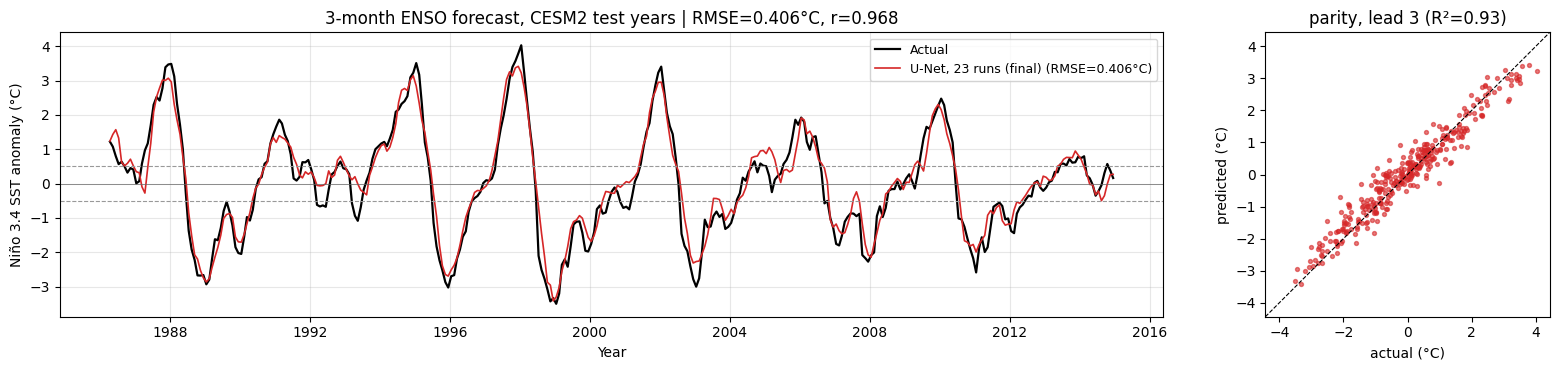

In [10]:
# lead 3: time series and parity plot
j = 2; ok = ~np.isnan(true_idx[:, j])
tgt_time = pd.to_datetime([f"{year[i]:04d}-{month[i]:02d}-15" for i in idx_test]) + pd.DateOffset(months=3)
s = skill[(skill.model == MODEL_NAME) & (skill.lead == 3)].iloc[0]
fig, ax = plt.subplots(1, 2, figsize=(16, 3.8), gridspec_kw={"width_ratios": [3.2, 1]})
ax[0].plot(tgt_time[ok], true_idx[ok, j], "k", lw=1.6, label="Actual")
ax[0].plot(tgt_time[ok], pred_idx[ok, j], color="tab:red", lw=1.2, label=f"{MODEL_NAME} (RMSE={s['RMSE']:.3f}°C)")
for v in (0.5, -0.5): ax[0].axhline(v, color="0.6", ls="--", lw=0.8)
ax[0].axhline(0, color="0.4", lw=0.5); ax[0].legend(frameon=True, fontsize=9); ax[0].grid(alpha=0.3)
ax[0].set(title=f"3-month ENSO forecast, CESM2 test years | RMSE={s['RMSE']:.3f}°C, r={s['corr']:.3f}", xlabel="Year",
          ylabel="Niño 3.4 SST anomaly (°C)")
lim = np.nanmax(np.abs(true_idx[ok, j])) * 1.1
ax[1].scatter(true_idx[ok, j], pred_idx[ok, j], s=8, alpha=0.6, color="tab:red")
ax[1].plot([-lim, lim], [-lim, lim], "k--", lw=0.8)
ax[1].set(xlim=(-lim, lim), ylim=(-lim, lim), aspect="equal", xlabel="actual (°C)", ylabel="predicted (°C)",
          title=f"parity, lead 3 (R²={s['R2']:.2f})")
plt.tight_layout(); plt.savefig(WORK / "figures" / f"{TAG}_test_lead3.png", dpi=150, bbox_inches="tight"); plt.show()

## 7. LIM baseline
The LIM is the standard linear ENSO model. We project the SST and sea-level maps on their leading EOFs and fit a one-month
linear step (next month = G x this month) on the same training years (r4 historical 1850-1955). For lead L we apply G
L times. The number of EOFs is picked on the validation years. The same LIM is used for the test years and, in Part B,
for the real-world data.

In [11]:
def lim_state(Rc, Zc):
    wt = np.sqrt(AREA_W[OCEAN])
    return np.concatenate([Rc / STD["R"] * wt, Zc / STD["Z"] * wt], 1)


def lim_apply(Rc, Zc, E, G):
    # LIM forecast for leads 1-12
    nc, wt = int(OCEAN.sum()), np.sqrt(AREA_W[OCEAN])
    p = lim_state(Rc, Zc) @ E.T; out = np.zeros((len(Rc), NL, nc), "float32"); Gl = np.eye(len(E))
    for j in range(NL):
        Gl = G @ Gl; out[:, j] = ((p @ Gl.T) @ E[:, :nc]) / wt * STD["R"]
    return out


tr = np.where((run_id == 0) & in_years(*TRAIN_YEARS))[0]
Vt = np.linalg.svd(lim_state(X["R"][tr], X["Z"][tr]), full_matrices=False)[2]


def fit_lim(k):
    E = Vt[:k]; Pc = lim_state(X["R"][tr], X["Z"][tr]) @ E.T
    return E, (Pc[1:].T @ Pc[:-1]) @ np.linalg.inv(Pc[:-1].T @ Pc[:-1])


val_true = np.array([nino_true[i + 3] for i in idx_val])
val_rmse = lambda k: np.sqrt(np.mean((nino_from_cells(lim_apply(X["R"][idx_val], X["Z"][idx_val], *fit_lim(k))[:, 2])
                                      - val_true) ** 2))
best_k = min((val_rmse(k), k) for k in (5, 10, 20, 30, 40, 60, 80))[1]
LIM_E, LIM_G = fit_lim(best_k)
lim_test = lim_apply(X["R"][idx_test], X["Z"][idx_test], LIM_E, LIM_G)
lim_idx = nino_from_cells(lim_test)
rows = []
for j, L in enumerate(LEADS):
    ok = ~np.isnan(true_idx[:, j])
    rows.append({"model": "LIM", "lead": L, "n": int(ok.sum()), **metrics(lim_idx[ok, j], true_idx[ok, j]),
                 "map ACC": map_acc(lim_test[ok, j], Rt[idx_test[ok] + L]).mean()})
lim_skill = pd.DataFrame(rows)
lim_skill.round(4).to_csv(WORK / "results" / "lim_cesm2_test_skill.csv", index=False)
print(f"LIM with {best_k} EOFs (chosen on validation), test years 1986-2014:")
lim_skill[lim_skill.lead.isin([1, 3, 6, 12])].set_index("lead").round(3)

LIM with 60 EOFs (chosen on validation), test years 1986-2014:


,model,n,corr,RMSE,MAE,bias,R2,map ACC
lead,,,,,,,,
1,LIM,347,0.986,0.257,0.201,0.001,0.973,0.894
3,LIM,345,0.943,0.519,0.413,0.007,0.889,0.778
6,LIM,342,0.840,0.856,0.692,0.016,0.699,0.665
12,LIM,336,0.658,1.214,0.960,0.027,0.404,0.504


In [12]:
# save what Part B needs
bundle = dict(model=MODEL_NAME, ocean=OCEAN, scale=SCALE, std=np.array(STD, dtype=object),
              test_start=np.array([f"{year[i]:04d}-{month[i]:02d}" for i in idx_test]), test_year=year[idx_test],
              test_month=month[idx_test], test_pred_idx=pred_idx, test_true_idx=true_idx, test_pers_idx=pers_idx,
              test_lead_acc=skill[skill.model == MODEL_NAME]["map ACC"].values)
if "LIM_E" in globals():
    bundle |= dict(lim_idx=lim_idx, lim_acc=lim_skill["map ACC"].values, lim_E=LIM_E, lim_G=LIM_G)
np.savez_compressed(WORK / "results" / f"{TAG}_preds.npz", **bundle)
print("saved", sorted(p.name for p in (WORK / "results").glob("*")), "and",
      len(list((WORK / "models").glob("*.pt"))), "checkpoints")

saved ['lim_cesm2_test_skill.csv', 'unet_23runs_cesm2_test_skill.csv', 'unet_23runs_preds.npz'] and 5 checkpoints


---
# Part B: real-world data (ecs289g_realworld_inputs_CESM2.nc)


In [6]:
B = dict(np.load(WORK / "results" / f"{TAG}_preds.npz", allow_pickle=True))
OCEAN, SCALE, STD = B["ocean"], float(B["scale"]), B["std"].item()
grid_tensors(OCEAN)
models = []
for f in sorted((WORK / "models").glob(f"{TAG}_seed*.pt")):
    ck = torch.load(f, map_location=DEV, weights_only=False)
    m = ARCHS[ck["arch"]](ck["ch_in"], NL, ck["width"]).to(DEV); m.load_state_dict(ck["state"]); m.eval(); models.append(m)
pred_idx, true_idx, pers_idx = B["test_pred_idx"], B["test_true_idx"], B["test_pers_idx"]
test_year, test_month = B["test_year"], B["test_month"]
print(f"reloaded {len(models)} trained networks ({MODEL_NAME}) and their CESM2 test results")

reloaded 5 trained networks (U-Net, 23 runs (final)) and their CESM2 test results


## 8. Real-world scores (Oct 2016 - Sep 2026)
This file is only used for evaluation and the forecast, not for training or tuning. It is processed the same way as
CESM2, except that the anomalies use the file's own 2016-2026 climatology because it has no 1985-2014 data.

In [7]:
cands = glob.glob("/kaggle/input/**/ecs289g_realworld_inputs_CESM2.nc", recursive=True) + \
        [str(Path.home() / "ENSO_project_export" / "ecs289g_realworld_inputs_CESM2.nc"), "ecs289g_realworld_inputs_CESM2.nc"]
REALWORLD_FILE = next((c for c in cands if Path(c).exists()), None)
print("real-world file:", REALWORLD_FILE)
NAMES = {"tos": ["tos", "sst"], "zos": ["zos", "ssh"], "mlotst": ["mlotst", "mld"], "tauu": ["tauu", "taux"],
         "tauv": ["tauv", "tauy"], "pr": ["pr", "precip"]}


def rw_field(ds, v):
    # one variable of the real-world file as anomalies on the grid
    da = ds[next(n for n in NAMES[v] if n in ds.variables)].squeeze(drop=True).astype("float32")
    latn = next(n for n in ("lat", "latitude", "nav_lat", "y") if n in da.coords)
    lonn = next(n for n in ("lon", "longitude", "nav_lon", "x") if n in da.coords)
    if v == "tos" and float(da.isel(time=-1).mean()) > 200: da = da - 273.15  # K to C
    if v == "pr" and float(abs(da).mean()) < 1e-2: da = da * 86400.0  # to mm/day
    if v == "mlotst" and float(da.mean()) > 2000: da = da / 100  # cm to m
    t = pd.to_datetime([f"{y:04d}-{m:02d}-15" for y, m in zip(*years_months(da.time.values))])
    da = da.assign_coords(time=t)
    da = (da.groupby("time.month") - da.groupby("time.month").mean("time")).drop_vars("month")
    lat, lon = da[latn].values, da[lonn].values % 360
    for d in [d for d in da.dims if d != "time" and d not in da[latn].dims + da[lonn].dims]: da = da.isel({d: 0})
    if lat.ndim == 1:
        lon2, lat2 = np.meshgrid(lon, lat); vals = da.transpose("time", latn, lonn).values
    else:
        lat2, lon2 = lat, lon; vals = da.values
    sel = (lat2 > -32) & (lat2 < 32) & (lon2 > 105) & (lon2 < 305)
    pts, vv = np.c_[lon2[sel], lat2[sel]], vals[:, sel]
    ok = np.isfinite(vv).mean(0) > 0.9
    vv = np.where(np.isfinite(vv), vv, np.nanmean(vv[:, ok], 1, keepdims=True))[:, ok]
    tgt = np.c_[GLON[OCEAN], GLAT[OCEAN]]
    g = LinearNDInterpolator(pts[ok], vv.T)(tgt)
    gap = ~np.isfinite(g).all(1)
    if gap.any(): g[gap] = NearestNDInterpolator(pts[ok], vv.T)(tgt[gap])
    return g.T.astype("float32")


if REALWORLD_FILE:
    ds = xr.open_dataset(REALWORLD_FILE, decode_times=xr.coders.CFDatetimeCoder(use_cftime=True))
    RWc = {v: rw_field(ds, v) for v in NAMES}
    raw_tauu = ds[next(n for n in NAMES["tauu"] if n in ds.variables)].sel(lat=slice(-5, 5), lon=slice(160, 240)).mean()
    if float(raw_tauu) > 0:  # trade winds should give tauu < 0
        print("tauu has the opposite sign convention -> flipping tauu and tauv"); RWc["tauu"] *= -1; RWc["tauv"] *= -1
    rw_year, rw_month = years_months(ds.time.values)
    rw_sst = RWc["tos"]
    RW = {"R": rw_sst - cell_mean(rw_sst, TROP, OCEAN)[:, None], "Z": RWc["zos"] - cell_mean(RWc["zos"], ALL, OCEAN)[:, None],
          **{v: RWc[v] for v in ("mlotst", "tauu", "tauv", "pr")}}
    rw_true = cell_mean(RW["R"], NINO34, OCEAN) * SCALE
    rw_trop = cell_mean(rw_sst, TROP, OCEAN)
    RWD = to_device(RW)
    rw_starts = np.arange(NLAG - 1, len(rw_year))
    rw_members = np.stack([predict(m, RWD, rw_month, rw_starts) for m in models])
    rw_member_idx = nino_from_cells(rw_members[..., OCEAN])
    rw_maps = rw_members.mean(0)
    rw_pred_idx = rw_member_idx.mean(0)
    rw_true_idx = np.array([[rw_true[i + L] if i + L < len(rw_true) else np.nan for L in LEADS] for i in rw_starts])
    rw_pers_idx = np.repeat(rw_true[rw_starts][:, None], NL, 1)
    rows = []
    for j, L in enumerate(LEADS):
        ok = ~np.isnan(rw_true_idx[:, j])
        rows.append({"model": MODEL_NAME, "lead": L, "n": int(ok.sum()), **metrics(rw_pred_idx[ok, j], rw_true_idx[ok, j])})
        rows.append({"model": "persistence", "lead": L, "n": int(ok.sum()), **metrics(rw_pers_idx[ok, j], rw_true_idx[ok, j])})
    rw_skill = pd.DataFrame(rows)
    rw_skill.round(4).to_csv(WORK / "results" / f"{TAG}_realworld_skill.csv", index=False)
    print("Real ocean, starts Dec 2016 onward, relative Niño 3.4")
    display(rw_skill[rw_skill.lead.isin([1, 3, 6, 12])].set_index(["lead", "model"]).round(3))
else:
    print("Real-world file not found: put ecs289g_realworld_inputs_CESM2.nc next to this notebook (or attach it on Kaggle).")

real-world file: /home/vikhas/ENSO_project_export/ecs289g_realworld_inputs_CESM2.nc


Real ocean, starts Dec 2016 onward, relative Niño 3.4


n   corr   RMSE    MAE   bias     R2
lead model                                                         
1    U-Net, 23 runs (final)  117  0.956  0.282  0.220 -0.046  0.875
     persistence             117  0.934  0.285  0.219 -0.027  0.872
3    U-Net, 23 runs (final)  115  0.890  0.496  0.403 -0.112  0.619
     persistence             115  0.691  0.604  0.475 -0.067  0.435
6    U-Net, 23 runs (final)  112  0.779  0.630  0.493 -0.110  0.401
     persistence             112  0.235  0.948  0.705 -0.086 -0.355
12   U-Net, 23 runs (final)  106  0.492  0.813  0.652  0.095  0.045
     persistence             106 -0.186  1.202  0.903 -0.089 -1.088

In [8]:
if REALWORLD_FILE:
    np.savez_compressed(WORK / "results" / f"{TAG}_realworld.npz", model=MODEL_NAME,
                        rw_start=np.array([f"{rw_year[i]:04d}-{rw_month[i]:02d}" for i in rw_starts]),
                        rw_pred_idx=rw_pred_idx, rw_member_idx=rw_member_idx, rw_true_idx=rw_true_idx)
    print("saved", f"{TAG}_realworld.npz")

saved unet_23runs_realworld.npz


## 9. Forecast for Dec 2026
The last month in the file is Sep 2026, so the 3-month forecast is for Dec 2026. The Jul and Aug starts give the Oct and
Nov forecasts, which can be checked later. The ± is the spread of the 5 seeds. Longer leads are only shown for context.
We save the forecast table (CSV) and the predicted SST fields (NetCDF).

3-month-ahead forecasts (lead 3), relative Niño 3.4 in °C:


,start,nino34_rel,seed_spread
target,,,
2026-10,2026-07,3.38,0.23
2026-11,2026-08,3.51,0.29
2026-12,2026-09,3.42,0.31


saved forecast_nino34_realworld.csv and forecast_sst_fields_realworld.nc


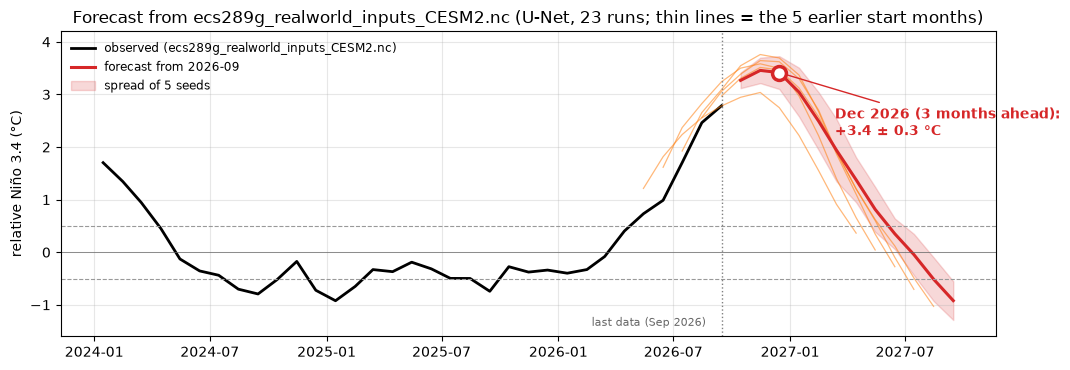

In [9]:
assert REALWORLD_FILE, "the forecast needs ecs289g_realworld_inputs_CESM2.nc"
rows = []
for i in range(len(rw_starts) - 6, len(rw_starts)):
    y0, m0 = rw_year[rw_starts[i]], rw_month[rw_starts[i]]
    for j, L in enumerate(LEADS):
        yy, mm = divmod(m0 - 1 + L, 12)
        rows.append({"start": f"{y0:04d}-{m0:02d}", "lead": L, "target": f"{y0 + yy:04d}-{mm + 1:02d}",
                     "nino34_rel": rw_member_idx[:, i, j].mean(), "seed_spread": rw_member_idx[:, i, j].std(),
                     "nino34_raw": float(rw_maps[i, j][OCEAN] @ w34c / w34c.sum() + rw_trop[rw_starts[i]])})
fc = pd.DataFrame(rows)
fc.round(3).to_csv(WORK / "results" / "forecast_nino34_realworld.csv", index=False)
print("3-month-ahead forecasts (lead 3), relative Niño 3.4 in °C:")
display(fc[fc.lead == 3][["start", "target", "nino34_rel", "seed_spread"]].round(2).tail(3).set_index("target"))

i = len(rw_starts) - 1
rel = np.where(OCEAN, rw_maps[i], np.nan)
last = fc[fc.start == fc.start.max()]
xr.Dataset({"sst_anom_rel_pred": (("lead", "lat", "lon"), rel.astype("float32")),
            "sst_anom_pred": (("lead", "lat", "lon"), (rel + rw_trop[rw_starts[i]]).astype("float32"))},
           coords={"lead": LEADS, "lat": LAT, "lon": LON, "target": ("lead", last.target.to_numpy(dtype="U7"))},
           attrs={"start": last.start.iloc[0], "model": MODEL_NAME + ", 5-seed mean",
                  "note": "anomaly vs the file's own 2016-2026 monthly climatology; rel = minus 20S-20N Pacific mean"}
           ).to_netcdf(WORK / "results" / "forecast_sst_fields_realworld.nc")
print("saved forecast_nino34_realworld.csv and forecast_sst_fields_realworld.nc")


# forecast plot: observed index and the forecasts from the last 6 start months
obs_t = pd.to_datetime([f"{y:04d}-{m:02d}-15" for y, m in zip(rw_year, rw_month)])
fc["t"] = pd.to_datetime(fc.target + "-15")
fig, ax = plt.subplots(figsize=(11, 3.8)); keep = obs_t >= "2024-01-01"
ax.plot(obs_t[keep], rw_true[keep], "k", lw=2, label=f"observed ({Path(REALWORLD_FILE).name})")
for s0, g in fc.groupby("start"):
    latest = s0 == fc.start.max()
    ax.plot(g.t, g.nino34_rel, color="tab:red" if latest else "tab:orange", lw=2.2 if latest else 0.9,
            alpha=1 if latest else 0.55, label=f"forecast from {s0}" if latest else None)
g = fc[fc.start == fc.start.max()]
ax.fill_between(g.t, g.nino34_rel - g.seed_spread, g.nino34_rel + g.seed_spread, color="tab:red", alpha=0.18,
                label="spread of 5 seeds")
d3 = g[g.lead == 3].iloc[0]
ax.plot(d3.t, d3.nino34_rel, "o", ms=10, mfc="white", mec="tab:red", mew=2.5, zorder=5)
ax.annotate(f"Dec 2026 (3 months ahead):\n{d3.nino34_rel:+.1f} ± {d3.seed_spread:.1f} °C", (d3.t, d3.nino34_rel),
            xytext=(40, -45), textcoords="offset points", fontsize=10, color="tab:red", fontweight="bold",
            arrowprops=dict(arrowstyle="-", color="tab:red"))
for v in (0.5, -0.5): ax.axhline(v, color="0.6", ls="--", lw=0.8)
ax.axhline(0, color="0.4", lw=0.5); ax.axvline(obs_t[-1], color="0.5", ls=":", lw=1)
ax.text(obs_t[-1] - pd.Timedelta(days=25), -1.4, "last data (Sep 2026)", fontsize=8, color="0.4", ha="right")
ax.set(ylabel="relative Niño 3.4 (°C)", ylim=(-1.6, 4.2),
       title=f"Forecast from {Path(REALWORLD_FILE).name} (U-Net, 23 runs; thin lines = the 5 earlier start months)")
ax.grid(alpha=0.3); ax.legend(fontsize=8.5, loc="upper left", frameon=False)
plt.tight_layout(); plt.savefig(WORK / "figures" / "forecast_dec2026.png", dpi=170, bbox_inches="tight"); plt.show()

## 10. Comparing all models
Notebooks 1 and 2 save their predictions (results/*_preds.npz and results/*_realworld.npz), which we copied into this
notebook's results folder. All models are scored on the same start months.

In [10]:
def lim_state(Rc, Zc):
    wt = np.sqrt(AREA_W[OCEAN])
    return np.concatenate([Rc / STD["R"] * wt, Zc / STD["Z"] * wt], 1)


def lim_apply(Rc, Zc, E, G):
    # LIM forecast for leads 1-12
    nc, wt = int(OCEAN.sum()), np.sqrt(AREA_W[OCEAN])
    p = lim_state(Rc, Zc) @ E.T; out = np.zeros((len(Rc), NL, nc), "float32"); Gl = np.eye(len(E))
    for j in range(NL):
        Gl = G @ Gl; out[:, j] = ((p @ Gl.T) @ E[:, :nc]) / wt * STD["R"]
    return out


P, RWP = {}, {}
for f in sorted((WORK / "results").glob("*_preds.npz")):
    z = dict(np.load(f, allow_pickle=True)); P[str(z["model"])] = z
for f in sorted((WORK / "results").glob("*_realworld.npz")):
    z = dict(np.load(f, allow_pickle=True)); RWP[str(z["model"])] = z
ORDER = [m for m in ["U-Net, 3 runs", "U-Net, 23 runs (final)", "ResNet, 23 runs"] if m in P]
print("models found:", ORDER)
COL = {"U-Net, 3 runs": "tab:orange", "U-Net, 23 runs (final)": "tab:red", "ResNet, 23 runs": "tab:blue",
       "persistence": "0.5", "LIM": "tab:green"}
lim_idx = B["lim_idx"]
lim_rw_idx = nino_from_cells(lim_apply(RW["R"][rw_starts], RW["Z"][rw_starts], B["lim_E"], B["lim_G"]))
test_preds = {m: P[m]["test_pred_idx"] for m in ORDER} | {"persistence": pers_idx, "LIM": lim_idx}
rw_preds = {m: RWP[m]["rw_pred_idx"] for m in ORDER if m in RWP} | {"persistence": rw_pers_idx, "LIM": lim_rw_idx}


def table(preds, truth):
    rows = []
    for m, p in preds.items():
        for j, L in enumerate(LEADS):
            ok = ~np.isnan(truth[:, j])
            rows.append({"model": m, "lead": L, **metrics(p[ok, j], truth[ok, j])})
    return pd.DataFrame(rows)


comp_test = table(test_preds, true_idx); comp_test.round(4).to_csv(WORK / "results" / "comparison_cesm2_test.csv", index=False)
comp_rw = table(rw_preds, rw_true_idx); comp_rw.round(4).to_csv(WORK / "results" / "comparison_realworld.csv", index=False)
acc3 = {m: float(P[m]["test_lead_acc"][2]) for m in ORDER} | {"LIM": float(B["lim_acc"][2])}
print("Lead 3 (the task), CESM2 test years 1986-2014:")
display(comp_test[comp_test.lead == 3].set_index("model")[["corr", "RMSE", "MAE", "R2"]]
        .assign(**{"map ACC": pd.Series(acc3)}).round(3))
print("Lead 3, real ocean 2016-2026:")
display(comp_rw[comp_rw.lead == 3].set_index("model")[["corr", "RMSE", "MAE", "R2"]].round(3))

models found: ['U-Net, 3 runs', 'U-Net, 23 runs (final)', 'ResNet, 23 runs']


Lead 3 (the task), CESM2 test years 1986-2014:


,corr,RMSE,MAE,R2,map ACC
model,,,,,
"U-Net, 3 runs",0.962,0.450,0.347,0.917,0.790
"U-Net, 23 runs (final)",0.968,0.406,0.313,0.932,0.808
"ResNet, 23 runs",0.967,0.420,0.325,0.927,0.811
persistence,0.788,1.015,0.795,0.575,NaN
LIM,0.943,0.519,0.413,0.889,0.778


Lead 3, real ocean 2016-2026:


,corr,RMSE,MAE,R2
model,,,,
"U-Net, 3 runs",0.874,0.467,0.372,0.663
"U-Net, 23 runs (final)",0.890,0.496,0.403,0.619
"ResNet, 23 runs",0.870,0.502,0.395,0.610
persistence,0.691,0.604,0.475,0.435
LIM,0.876,0.479,0.385,0.645


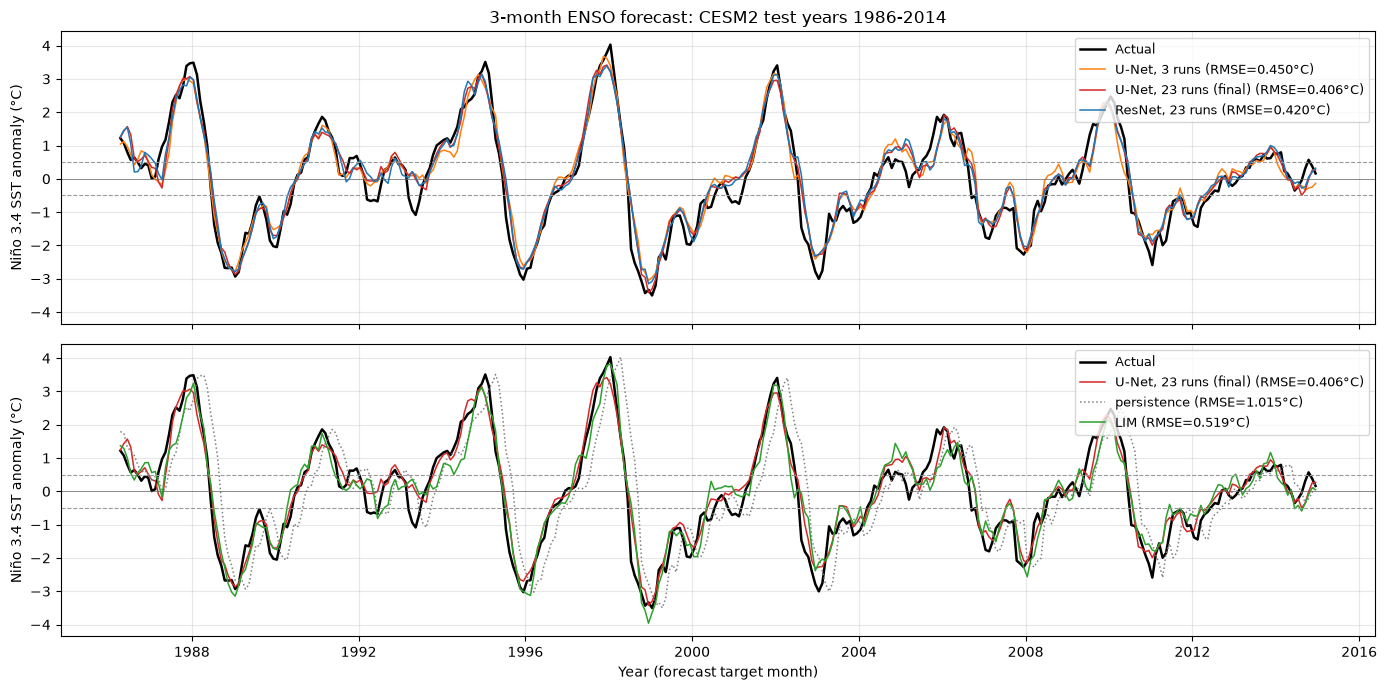

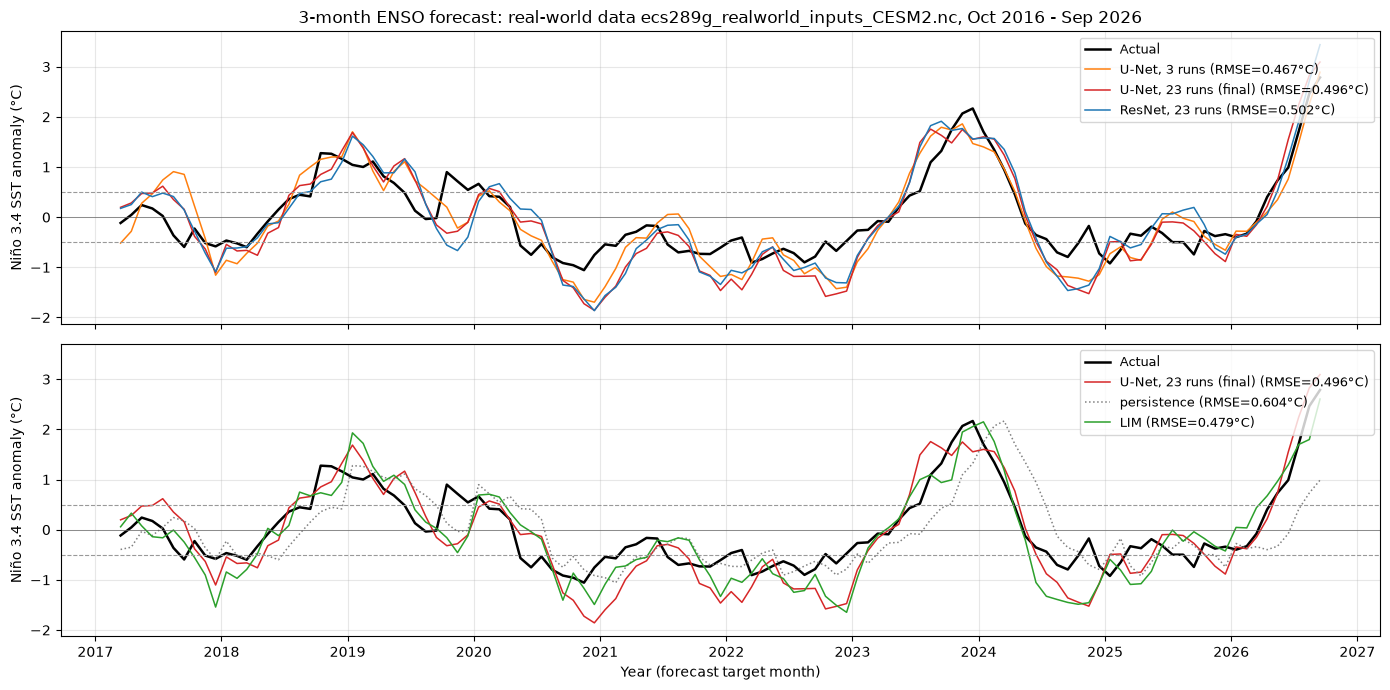

In [11]:
# lead 3 time series for all models
def ts_figure(preds, truth, start_years, start_months, comp, title, fname):
    j = 2; ok = ~np.isnan(truth[:, j])
    tt = pd.to_datetime([f"{y:04d}-{m:02d}-15" for y, m in zip(start_years, start_months)]) + pd.DateOffset(months=3)
    rm = comp[comp.lead == 3].set_index("model").RMSE
    groups = [[m for m in ORDER if m in preds], [m for m in ["U-Net, 23 runs (final)", "persistence", "LIM"] if m in preds]]
    fig, axs = plt.subplots(2, 1, figsize=(14, 7), sharex=True, sharey=True)
    for ax, g in zip(axs, groups):
        ax.plot(tt[ok], truth[ok, j], "k", lw=1.8, label="Actual")
        for m in g:
            ax.plot(tt[ok], preds[m][ok, j], color=COL[m], lw=1.1, ls=":" if m == "persistence" else "-",
                    label=f"{m} (RMSE={rm[m]:.3f}°C)")
        for v in (0.5, -0.5): ax.axhline(v, color="0.6", ls="--", lw=0.8)
        ax.axhline(0, color="0.4", lw=0.5); ax.grid(alpha=0.3); ax.legend(fontsize=9, loc="upper right")
        ax.set_ylabel("Niño 3.4 SST anomaly (°C)")
    axs[0].set_title(title); axs[1].set_xlabel("Year (forecast target month)")
    plt.tight_layout(); plt.savefig(WORK / "figures" / fname, dpi=150, bbox_inches="tight"); plt.show()


ts_figure(test_preds, true_idx, test_year, test_month, comp_test,
          "3-month ENSO forecast: CESM2 test years 1986-2014", "compare_timeseries_cesm2_test.png")
if REALWORLD_FILE:
    ts_figure(rw_preds, rw_true_idx, rw_year[rw_starts], rw_month[rw_starts], comp_rw,
              f"3-month ENSO forecast: real-world data {Path(REALWORLD_FILE).name}, Oct 2016 - Sep 2026",
              "compare_timeseries_realworld.png")

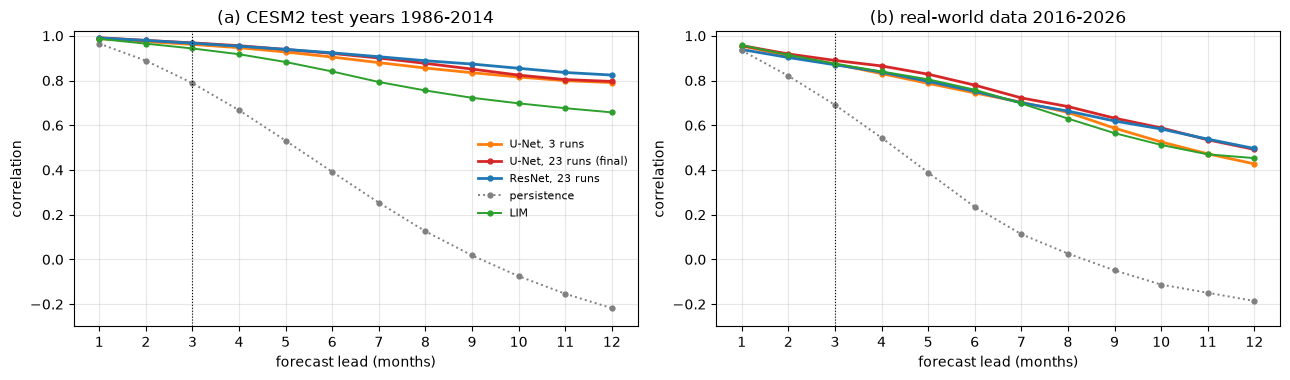

In [12]:
# correlation vs lead for all models
panels = [("CESM2 test years 1986-2014", comp_test)] + ([("real-world data 2016-2026", comp_rw)] if REALWORLD_FILE else [])
fig, axs = plt.subplots(1, len(panels), figsize=(6.5 * len(panels), 3.9), squeeze=False)
for c, (name, comp) in enumerate(panels):
    ax = axs[0, c]
    for m in ORDER + ["persistence", "LIM"]:
        d = comp[comp.model == m]
        if d.empty: continue
        ax.plot(d.lead, d["corr"], color=COL[m], lw=2 if m in ORDER else 1.4, ls=":" if m == "persistence" else "-",
                marker="o", ms=3.5, label=m)
    ax.axvline(3, color="k", lw=0.8, ls=":"); ax.set_xticks(LEADS); ax.grid(alpha=0.3)
    ax.set(title=f"({'ab'[c]}) {name}", xlabel="forecast lead (months)", ylabel="correlation", ylim=(-0.3, 1.02))
axs[0, 0].legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.savefig(WORK / "figures" / "compare_skill_vs_lead.png", dpi=150, bbox_inches="tight"); plt.show()

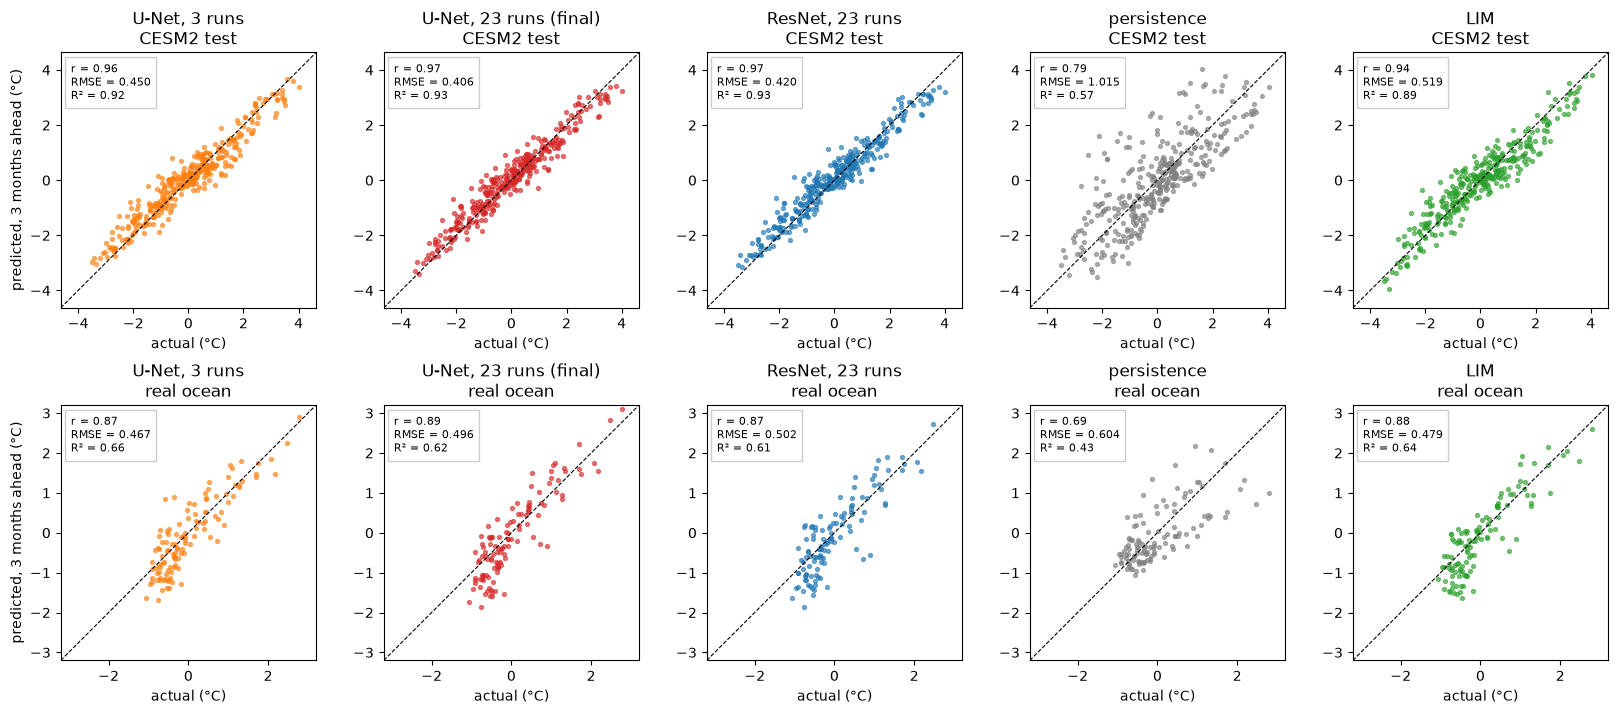

In [13]:
# parity plots at lead 3
sets = [("CESM2 test", test_preds, true_idx, comp_test)] + ([("real ocean", rw_preds, rw_true_idx, comp_rw)] if REALWORLD_FILE else [])
cols = ORDER + ["persistence", "LIM"]
fig, axs = plt.subplots(len(sets), len(cols), figsize=(3.3 * len(cols), 3.5 * len(sets)), squeeze=False)
for r, (name, preds, truth, comp) in enumerate(sets):
    ok = ~np.isnan(truth[:, 2]); lim_ = np.nanmax(np.abs(truth[ok, 2])) * 1.15
    for c, m in enumerate(cols):
        ax = axs[r, c]
        if m not in preds: ax.axis("off"); continue
        s = comp[(comp.model == m) & (comp.lead == 3)].iloc[0]
        ax.scatter(truth[ok, 2], preds[m][ok, 2], s=8, alpha=0.6, color=COL[m])
        ax.plot([-lim_, lim_], [-lim_, lim_], "k--", lw=0.8)
        ax.text(0.04, 0.96, f"r = {s['corr']:.2f}\nRMSE = {s['RMSE']:.3f}\nR² = {s['R2']:.2f}", transform=ax.transAxes, va="top",
                fontsize=8, bbox=dict(fc="white", ec="0.8"))
        ax.set(xlim=(-lim_, lim_), ylim=(-lim_, lim_), aspect="equal", title=f"{m}\n{name}", xlabel="actual (°C)")
        if c == 0: ax.set_ylabel("predicted, 3 months ahead (°C)")
plt.tight_layout(h_pad=2.5); plt.savefig(WORK / "figures" / "compare_parity_lead3.png", dpi=150, bbox_inches="tight"); plt.show()

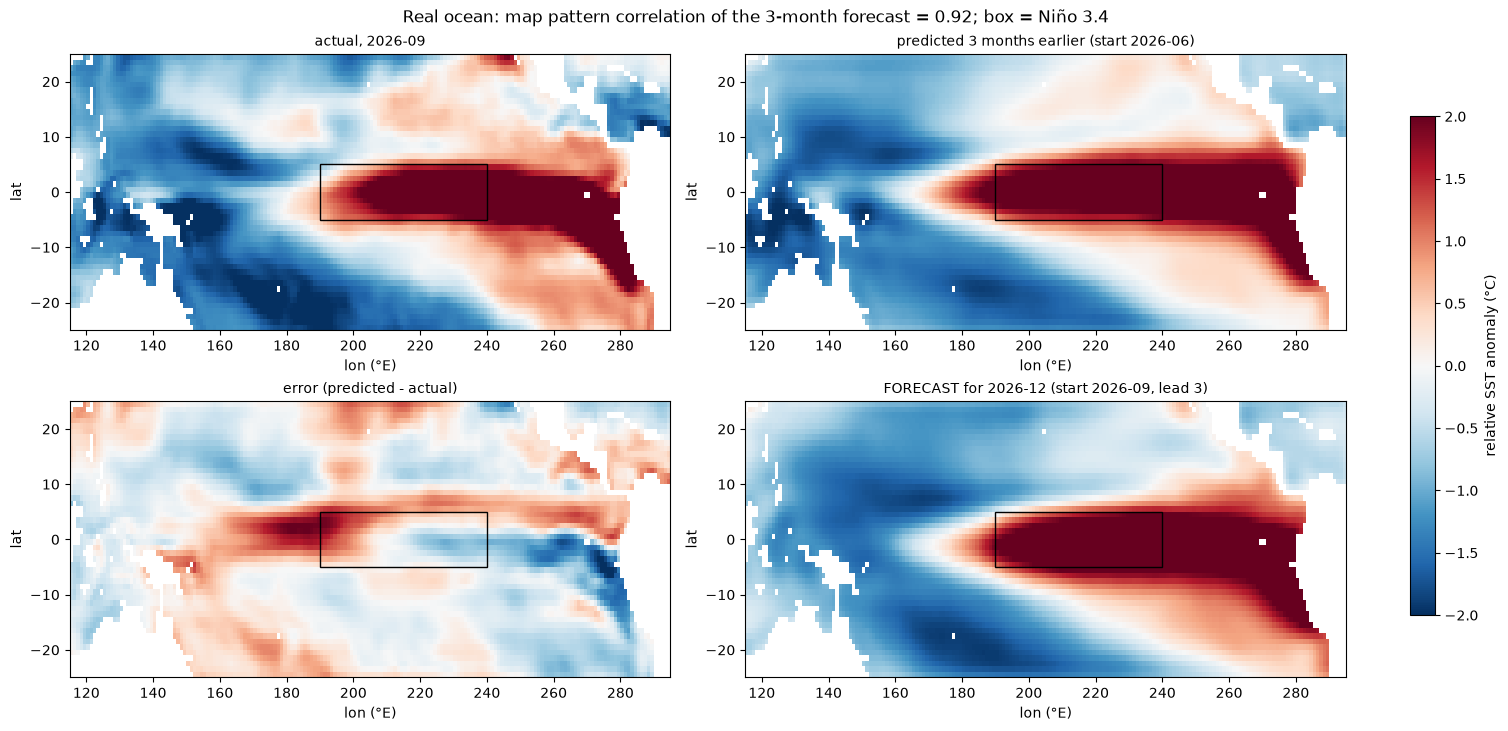

In [14]:
# maps: actual vs predicted on real data, plus the Dec 2026 forecast
def grid(cells):
    g = np.full(OCEAN.shape, np.nan); g[OCEAN] = cells; return g


ok3 = ~np.isnan(rw_true_idx[:, 2])
k = int(np.nanargmax(np.where(ok3, rw_true_idx[:, 2], -np.inf)))
tk = rw_starts[k] + 3
actual, predicted = grid(RW["R"][tk]), rw_maps[k, 2]
predicted = np.where(OCEAN, predicted, np.nan)
P_, Y_ = predicted[OCEAN], actual[OCEAN]
acc_k = map_acc(P_[None], Y_[None])[0]
panels = [(f"actual, {rw_year[tk]}-{rw_month[tk]:02d}", actual),
          (f"predicted 3 months earlier (start {rw_year[rw_starts[k]]}-{rw_month[rw_starts[k]]:02d})", predicted),
          ("error (predicted - actual)", predicted - actual),
          (f"FORECAST for {fc[fc.lead == 3].target.iloc[-1]} (start {fc.start.max()}, lead 3)", np.where(OCEAN, rw_maps[-1, 2], np.nan))]
fig, axs = plt.subplots(2, 2, figsize=(15, 7.2), constrained_layout=True)
for ax, (title, f) in zip(axs.ravel(), panels):
    im = ax.pcolormesh(LON, LAT, f, cmap="RdBu_r", vmin=-2, vmax=2, shading="auto")
    ax.add_patch(plt.Rectangle((190, -5), 50, 10, fill=False, ec="k")); ax.set_title(title, fontsize=10)
    ax.set(xlabel="lon (°E)", ylabel="lat")
fig.colorbar(im, ax=axs, label="relative SST anomaly (°C)", shrink=0.8)
fig.suptitle(f"Real ocean: map pattern correlation of the 3-month forecast = {acc_k:.2f}; box = Niño 3.4")
plt.savefig(WORK / "figures" / "compare_maps_realworld.png", dpi=150, bbox_inches="tight"); plt.show()

## Summary
- On the CESM2 test years all three networks beat the LIM and persistence at every lead (lead 3: U-Net 0.41 °C RMSE,
  LIM 0.52 °C, persistence 1.02 °C).
- Going from 3 to 23 training runs helped; the bigger ResNet did not.
- On the real-world data the networks clearly beat persistence, but the LIM is about as good at lead 3 (correlation 0.89
  vs 0.88).
- No simulated or real 2016-2026 data was used for training or validation.
